# Preentrega 10: Modelado y evaluación de clasificación (Churn)

**Problema:** una empresa de telecomunicaciones quiere anticipar qué clientes van a darse de baja (*churn*) para ofrecerles una acción de retención a tiempo.

**Objetivo:** entrenar un modelo de **Regresión Logística** que prediga `churn` (1 = se va, 0 = se queda) y evaluarlo con Accuracy, Precision, Recall, F1 y matriz de confusión.

**Datos:** `data/clientes_churn.csv` (dataset simulado con la estructura de un caso Telco clásico). Si el archivo no existe, el notebook lo genera automáticamente con semilla fija.

## Dónde se cumple cada criterio de la rúbrica

| Criterio | Dónde está en este notebook |
|---|---|
| 1. Notebook ejecutable con división Train/Test (80/20) | Secciones 1 y 2 (`train_test_split`, `test_size=0.20`) |
| 2. Al menos 4 métricas (Accuracy, Precision, Recall, F1) | Sección 4 (tabla de métricas) |
| 3. Matriz de confusión visible (mapa de calor) | Sección 5 (también guardada en `resultados/matriz_confusion.png`) |
| 4. README con descripción e instrucciones de ejecución | Archivo `README.md` del repositorio |
| 5. Conclusión que vincula métricas con el negocio | Sección 7 (celda Markdown) |

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

SEED = 42  # semilla fija para que los resultados sean reproducibles
Path("resultados").mkdir(exist_ok=True)   # carpeta donde se guardan las evidencias

## 1. Carga y revisión de los datos

In [2]:
RUTA = Path("data/clientes_churn.csv")

if not RUTA.exists():
    # Plan B: si el CSV no está en el repositorio, se genera con la misma receta de generar_dataset.py
    Path("data").mkdir(exist_ok=True)
    rng = np.random.default_rng(10)
    n = 3000
    antig = rng.integers(1, 73, n)
    contrato = rng.choice(["Mensual", "Anual", "Bianual"], n, p=[0.55, 0.25, 0.20])
    internet = rng.choice(["DSL", "Fibra", "Ninguno"], n, p=[0.35, 0.45, 0.20])
    pago = rng.choice(["Tarjeta", "Transferencia", "Cheque", "Debito"], n)
    soporte = rng.choice(["Si", "No"], n, p=[0.4, 0.6])
    cargo = (30 + 25 * (internet == "Fibra") + 12 * (internet == "DSL") + rng.normal(0, 8, n)).round(2)
    total = (cargo * antig + rng.normal(0, 40, n)).clip(20).round(2)
    logit = (-0.6 - 0.045 * antig + 0.018 * cargo + 1.3 * (contrato == "Mensual")
             - 0.8 * (contrato == "Bianual") + 0.5 * (pago == "Cheque") - 0.5 * (soporte == "Si"))
    churn = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
    pd.DataFrame({"antiguedad_meses": antig, "cargo_mensual": cargo, "cargos_totales": total,
                  "tipo_contrato": contrato, "servicio_internet": internet, "metodo_pago": pago,
                  "soporte_tecnico": soporte, "churn": churn}).to_csv(RUTA, index=False)
    print("El CSV no existía: se generó data/clientes_churn.csv")

df = pd.read_csv(RUTA)
print("Filas y columnas:", df.shape)
print("Valores nulos por columna:")
print(df.isna().sum())
df.head()

Filas y columnas: (3000, 8)
Valores nulos por columna:
antiguedad_meses     0
cargo_mensual        0
cargos_totales       0
tipo_contrato        0
servicio_internet    0
metodo_pago          0
soporte_tecnico      0
churn                0
dtype: int64


   antiguedad_meses  cargo_mensual  ...  soporte_tecnico churn
0                56          25.13  ...               No     0
1                69          56.21  ...               Si     1
2                20          28.89  ...               Si     1
3                15          55.05  ...               No     1
4                58          56.64  ...               No     1

[5 rows x 8 columns]

In [3]:
# Proporción de clientes que abandonan (clases desbalanceadas)
print(df["churn"].value_counts(normalize=True).round(3))

churn
0    0.654
1    0.346
Name: proportion, dtype: float64


## 2. División Train/Test (80/20)
Se separa **antes** de cualquier ajuste de preprocesamiento para evitar *data leakage*. `stratify=y` mantiene la misma proporción de churn en ambos conjuntos.

In [4]:
X = df.drop(columns=["churn"])
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print("Entrenamiento (80%):", X_train.shape, "| Prueba (20%):", X_test.shape)

Entrenamiento (80%): (2400, 7) | Prueba (20%): (600, 7)


## 3. Modelo: preprocesamiento + Regresión Logística
Se usa `class_weight="balanced"` porque los clientes que se van son minoría y no queremos que el modelo los ignore.

In [5]:
cols_num = X.select_dtypes(include="number").columns.tolist()
cols_cat = X.select_dtypes(exclude="number").columns.tolist()

preprocesador = ColumnTransformer([
    ("num", StandardScaler(), cols_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cols_cat),
])

modelo = Pipeline([
    ("prep", preprocesador),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
])
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)
print("Modelo entrenado")

Modelo entrenado


## 4. Métricas sobre el conjunto de prueba (criterio 2)

In [6]:
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)

tabla = pd.DataFrame({"Métrica": ["Accuracy", "Precision", "Recall", "F1-Score"],
                      "Valor": [acc, prec, rec, f1]}).round(3)
tabla.to_csv("resultados/metricas.csv", index=False)   # evidencia guardada en el repositorio
tabla

     Métrica  Valor
0   Accuracy  0.730
1  Precision  0.587
2     Recall  0.745
3   F1-Score  0.657

In [7]:
print(classification_report(y_test, y_pred, target_names=["Se queda (0)", "Se va (1)"]))

              precision    recall  f1-score   support

Se queda (0)       0.84      0.72      0.78       392
   Se va (1)       0.59      0.75      0.66       208

    accuracy                           0.73       600
   macro avg       0.71      0.73      0.72       600
weighted avg       0.75      0.73      0.74       600



## 5. Matriz de confusión (mapa de calor) (criterio 3)

Verdaderos negativos: 283 | Falsos positivos: 109 | Falsos negativos: 53 | Verdaderos positivos: 155


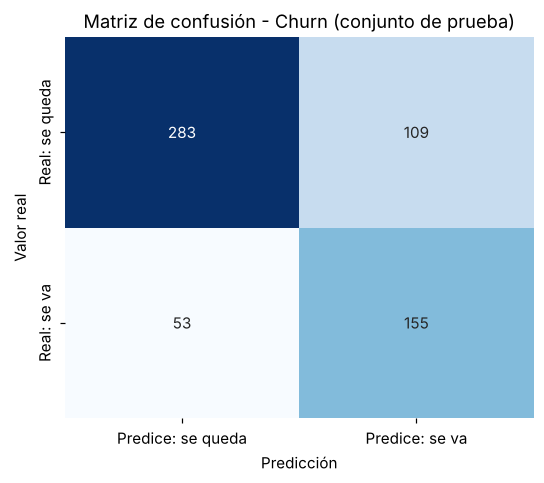

In [8]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predice: se queda", "Predice: se va"],
            yticklabels=["Real: se queda", "Real: se va"])
plt.title("Matriz de confusión - Churn (conjunto de prueba)")
plt.ylabel("Valor real"); plt.xlabel("Predicción")
plt.savefig("resultados/matriz_confusion.png", dpi=130, bbox_inches="tight")   # evidencia guardada
plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"Verdaderos negativos: {tn} | Falsos positivos: {fp} | Falsos negativos: {fn} | Verdaderos positivos: {tp}")

## 6. Impacto económico (supuestos de negocio)
Supuestos **ilustrativos**: perder un cliente cuesta 300 (ingreso futuro perdido) y una oferta de retención cuesta 30.

In [9]:
COSTO_FN = 300   # cliente que se va y no lo detectamos
COSTO_FP = 30    # oferta enviada a un cliente que no se iba a ir

costo_modelo = fn * COSTO_FN + fp * COSTO_FP
costo_sin_modelo = (fn + tp) * COSTO_FN   # sin modelo se pierden todos los que se van
print(f"Costo estimado SIN modelo : {costo_sin_modelo:,.0f}")
print(f"Costo estimado CON modelo : {costo_modelo:,.0f}")
print(f"Ahorro estimado           : {costo_sin_modelo - costo_modelo:,.0f}")

Costo estimado SIN modelo : 62,400
Costo estimado CON modelo : 19,170
Ahorro estimado           : 43,230


## 7. Interpretación y conclusión de negocio (criterio 5 de la rúbrica)

**¿Qué métrica es la más importante en Churn? El Recall.**

- Un **falso negativo (FN)** es un cliente que se iba a ir y el modelo dijo que se quedaba. No recibe ninguna oferta y **se pierde**. Conseguir un cliente nuevo cuesta mucho más que retener uno actual, así que es el error más caro.
- Un **falso positivo (FP)** es un cliente que se quedaba y recibió una oferta de más. Cuesta una promoción, un costo bastante menor.
- Por eso conviene maximizar el **Recall** (de todos los que se van, cuántos detectamos), cuidando que la **Precision** no se desplome para no gastar de más en ofertas. El **F1** resume ese equilibrio.
- El **Accuracy** engaña con clases desbalanceadas: un modelo que dijera "nadie se va" acertaría aproximadamente en el 65% de los casos y no detectaría a ningún cliente en riesgo.

**Resultados obtenidos:** Accuracy 0.73, Precision 0.59, **Recall 0.75**, F1 0.66. El modelo detecta 75% de los clientes que se van, con 53 falsos negativos sobre 208 clientes que realmente abandonaron en el conjunto de prueba. En términos de negocio, permite dirigir las ofertas de retención a quienes tienen más riesgo en lugar de enviarlas a ciegas.

**Próximos pasos:** ajustar el umbral de decisión, probar Random Forest y optimizar hiperparámetros.